<a href="https://colab.research.google.com/github/minsung-kim-dev/Vectorizing-Raster-Maps/blob/main/notebooks/raster2seq_smoke_test.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Raster2Seq stage-1 (shapes only) smoke test

Trains Raster2Seq for a few steps on a handful of OSM crops, to check that the data, model and loss work together. With so few images the model should start memorising them: the token-type loss (`loss_ce`) drops within a few passes, the coordinate loss (`loss_coords`) more slowly. This is a pipeline check, not a useful model.

Runs on Google Colab (GPU or CPU) or locally in the `raster2seq` env. On Colab: **Runtime → Change runtime type → GPU** is faster but optional.

What it does:
1. Installs Raster2Seq and its dependencies (Colab only)
2. Loads a small COCO dataset (`coco_osm_mini.zip`, made by `data_preprocess/create_coco_osm.py`)
3. Patches three things so Raster2Seq runs outside `main_ddp.py` (no multi-GPU setup, no wandb)
4. Builds the model with the stage-1 settings from Raster2Seq's `tools/train_cc5k.sh` (`--semantic_classes -1`)
5. Trains for a few steps and plots the loss

## 1. Settings

In [ ]:
import os, sys

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    R2S = "/content/Raster2Seq"           # cloned below
    DATA = "/content/coco_osm_mini"       # unzipped from the uploaded coco_osm_mini.zip
else:
    R2S = os.path.abspath("../../Raster2Seq")
    DATA = os.path.abspath("../data/coco_osm_mini")

SPLIT = "train"      # which split to train on
N_IMAGES = 2         # how many images to use
BATCH_SIZE = 2
STEPS = 1000          # passes over the N_IMAGES images
IMAGE_SIZE = 512     # 512 is closer to real training but ~4x slower
SEQ_LEN = 2048        # shapes past this many tokens are dropped
NUM_BINS = 32        # grid size for position tokens
PRETRAINED = True    # ImageNet ResNet-50 weights (downloaded automatically, ~100 MB); False = random init

## 2. Install (Colab only)

Clones Raster2Seq and installs the packages its training code imports (Colab already has torch, numpy, opencv, shapely, …). On a GPU runtime it also compiles Raster2Seq's deformable-attention CUDA op; if that fails (or on CPU) step 4 falls back to Raster2Seq's plain-PyTorch version, which is slower but equivalent.

In [ ]:
import subprocess, torch

def sh(cmd):
    print("$", cmd)
    subprocess.run(cmd, shell=True, check=True)

FORK = "https://github.com/jennahgosciak/Raster2Seq.git"
BRANCH = "osm-changes"

if IN_COLAB:
    if not os.path.exists(R2S):
        sh(f"git clone -q -b {BRANCH} {FORK} {R2S}")
    else:   # already cloned in this session: get the latest commits on the branch
        sh(f"git -C {R2S} fetch -q origin {BRANCH} && git -C {R2S} checkout -q {BRANCH} && git -C {R2S} reset -q --hard origin/{BRANCH}")
    sh(f"git -C {R2S} log -1 --format='Raster2Seq %h %s'")   # shows which commit you're on
    sh("pip install -q pycocotools descartes einops fvcore iopath omegaconf cloudpickle plotly scikit-image")
    if torch.cuda.is_available():
        try:
            sh(f"cd {R2S}/models/ops && python setup.py build install > build.log 2>&1")
        except subprocess.CalledProcessError:
            print(f"Compiling the CUDA op failed (see {R2S}/models/ops/build.log); using the PyTorch fallback.")



$ git -C /content/Raster2Seq fetch -q origin osm-changes && git -C /content/Raster2Seq checkout -q osm-changes && git -C /content/Raster2Seq reset -q --hard origin/osm-changes
$ git -C /content/Raster2Seq log -1 --format='Raster2Seq %h %s'
$ pip install -q pycocotools descartes einops fvcore iopath omegaconf cloudpickle plotly scikit-image
$ cd /content/Raster2Seq/models/ops && python setup.py build install > build.log 2>&1
Compiling the CUDA op failed (see /content/Raster2Seq/models/ops/build.log); using the PyTorch fallback.


## 3. Data

On Colab, upload `coco_osm_mini.zip` from this repo's `data/` folder when prompted (or copy it from Google Drive). It's a 40-crop dataset in the layout Raster2Seq expects: `{train,val,test}/*.png` + `annotations/{split}.json`.

In [ ]:
if IN_COLAB and not os.path.exists(DATA):
    from google.colab import files
    files.upload()                       # choose coco_osm_mini.zip
    sh("unzip -q coco_osm_mini.zip -d /content")

print(sorted(os.listdir(DATA)), "|", len(os.listdir(f"{DATA}/{SPLIT}")), f"{SPLIT} images")

['annotations', 'test', 'train', 'val'] | 26 train images


## 4. Patches

Three workarounds so Raster2Seq runs here without editing its code:
- **wandb** – `main_ddp.py` imports it for logging; a stub module avoids installing/configuring it.
- **Deformable attention** – the compiled CUDA op is used when available on a GPU; otherwise Raster2Seq's plain-PyTorch reference implementation (`ms_deform_attn_core_pytorch`).
- **Annotations edited in place** – Raster2Seq's loader resizes annotations inside its COCO object, so loading an image twice shrinks its shapes again. We hand it a copy each time.

In [ ]:
import types, copy, torch

sys.path.insert(0, R2S)
sys.modules.setdefault("wandb", types.ModuleType("wandb"))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
try:
    import MultiScaleDeformableAttention  # noqa: F401  (compiled CUDA op)
    use_pytorch_attn = device.type == "cpu"
except ImportError:
    sys.modules["MultiScaleDeformableAttention"] = types.ModuleType("MultiScaleDeformableAttention")
    use_pytorch_attn = True

from models.ops.functions import MSDeformAttnFunction, ms_deform_attn_func

if use_pytorch_attn:
    MSDeformAttnFunction.apply = staticmethod(
        lambda value, shapes, level_start, locations, weights, im2col_step:
        ms_deform_attn_func.ms_deform_attn_core_pytorch(value, shapes, locations, weights)
    )

if not PRETRAINED:
    import torchvision
    _resnet50 = torchvision.models.resnet50
    torchvision.models.resnet50 = lambda **kw: _resnet50(**{**kw, "pretrained": False})

print("device:", device, "| deformable attention:", "PyTorch fallback" if use_pytorch_attn else "compiled CUDA op")

device: cuda | deformable attention: compiled CUDA op


## 5. Config

Stage-1 settings from Raster2Seq's `tools/train_cc5k.sh`, adapted to the OSM data:
- `--semantic_classes -1` – shapes only, no labels
- `--dataset_name waffle` – resize + pad to a square, keep all categories
- `--input_channels 3` – RGB maps
- `disable_image_transform` – no random flips/rotations, so the model can memorise the few images

In [ ]:
import argparse
from main_ddp import get_args_parser

args = argparse.ArgumentParser(parents=[get_args_parser()]).parse_args([
    "--dataset_name", "waffle", "--dataset_root", DATA,
    "--semantic_classes", "-1", "--input_channels", "3",
    "--poly2seq", "--seq_len", str(SEQ_LEN), "--num_bins", str(NUM_BINS), "--image_size", str(IMAGE_SIZE), "--row_tolerance", "0.08",  # rows 8% of the image height (reading order)
    "--batch_size", str(BATCH_SIZE), "--num_workers", "0", "--device", device.type,
    "--label_smoothing", "0", "--cls_loss_coef", "5", "--coords_loss_coef", "20",
    "--disable_poly_refine", "--dec_attn_concat_src", "--use_anchor", "--converter_version", "v3",
])
args.with_poly_refine = not args.disable_poly_refine   # main_ddp.py applies this after parsing
args.disable_image_transform = True   # not a main_ddp.py option, but the data loader reads it

## 6. Data loader

In [ ]:
from torch.utils.data import DataLoader, Subset
from datasets import build_dataset

dataset = build_dataset(image_set=SPLIT, args=args)
_load_anns = dataset.coco.loadAnns
dataset.coco.loadAnns = lambda ids: copy.deepcopy(_load_anns(ids))   # see patches above
args.vocab_size = dataset.get_vocab_size()

# the sequence tensors to batch together (same as main_ddp.py's collator)
SEQ_KEYS = ["delta_x1", "delta_x2", "delta_y1", "delta_y2", "seq11", "seq21", "seq12", "seq22",
            "target_seq", "token_labels", "mask", "target_polygon_labels"]

def collate(batch):
    return batch, {k: torch.stack([item.pop(k) for item in batch]) for k in SEQ_KEYS}

loader = DataLoader(Subset(dataset, range(min(N_IMAGES, len(dataset)))),
                    batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate, num_workers=0)
print(len(loader.dataset), "images,", len(loader), "batches per pass")

Build waffle train dataset
loading annotations into memory...
Done (t=0.06s)
creating index...
index created!
2 images, 1 batches per pass


## 7. Model

In [ ]:
from models import build_model

model, criterion = build_model(args, tokenizer=dataset.get_tokenizer())
model.to(device)
criterion.to(device)
optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad],
                              lr=args.lr, weight_decay=args.weight_decay)
scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, [int(STEPS * 0.8)])
print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.1f}M parameters")

47.2M parameters


In [ ]:
from raster2seq_hub import download_checkpoint

START_FROM = "s3d-bw"   # train_cc5k.sh's starting point; or "cubicasa5k"; None = train from scratch

if START_FROM:
    path = download_checkpoint(START_FROM)   # downloads once from Hugging Face, then cached
    ckpt = torch.load(path, map_location="cpu", weights_only=False)["model"]
    state = model.state_dict()
    usable = {k: v for k, v in ckpt.items() if k in state and v.shape == state[k].shape}
    skipped = sorted(k for k in ckpt if k not in usable)
    model.load_state_dict(usable, strict=False)
    print(f"{START_FROM}: loaded {len(usable)} of {len(state)} weights, skipped {len(skipped)}")
    print("skipped:", skipped[:10])

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

s3d-bw: loaded 607 of 614 weights, skipped 9
skipped: ['attention_mask', 'input_proj.0.0.weight', 'input_proj.1.0.weight', 'input_proj.2.0.weight', 'input_proj.3.0.weight', 'query_embed.weight', 'room_class_embed.bias', 'room_class_embed.weight', 'transformer.pos_embed']


## 8. Train

Same step as Raster2Seq's `engine.train_one_epoch`: the decoder sees the true previous tokens, and the loss combines token type (corner / separator / end, `loss_ce`) and coordinates (`loss_coords`), weighted by `--cls_loss_coef` and `--coords_loss_coef`.

In [ ]:
import time

history = []
model.train(); criterion.train()
for step in range(STEPS):
    t0 = time.time()
    for batch, extras in loader:
        samples = [item["image"].to(device) for item in batch]
        extras = {k: v.to(device) for k, v in extras.items()}
        loss_dict = criterion(model(samples, extras), extras)
        weights = criterion.weight_dict
        loss = sum(loss_dict[k] * weights[k] for k in loss_dict if k in weights)

        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), args.clip_max_norm)
        optimizer.step()

        history.append({k: float(loss_dict[k]) for k in weights if k in loss_dict} | {"total": loss.item()})
    scheduler.step()
    parts = ", ".join(f"{k} {v:.3f}" for k, v in history[-1].items())
    print(f"pass {step + 1}/{STEPS} ({time.time() - t0:.1f}s): {parts}")

pass 1/1000 (1.1s): loss_ce 1.801, loss_coords 0.323, total 15.460
pass 2/1000 (1.1s): loss_ce 0.896, loss_coords 0.192, total 8.323
pass 3/1000 (1.1s): loss_ce 0.632, loss_coords 0.136, total 5.883
pass 4/1000 (1.1s): loss_ce 0.586, loss_coords 0.118, total 5.287
pass 5/1000 (1.1s): loss_ce 0.589, loss_coords 0.104, total 5.021
pass 6/1000 (1.2s): loss_ce 0.560, loss_coords 0.091, total 4.618
pass 7/1000 (0.8s): loss_ce 0.546, loss_coords 0.089, total 4.504
pass 8/1000 (0.8s): loss_ce 0.523, loss_coords 0.079, total 4.191
pass 9/1000 (0.8s): loss_ce 0.517, loss_coords 0.078, total 4.149
pass 10/1000 (0.9s): loss_ce 0.492, loss_coords 0.072, total 3.902
pass 11/1000 (0.9s): loss_ce 0.490, loss_coords 0.078, total 4.004
pass 12/1000 (0.9s): loss_ce 0.484, loss_coords 0.071, total 3.849
pass 13/1000 (0.9s): loss_ce 0.477, loss_coords 0.068, total 3.735
pass 14/1000 (0.9s): loss_ce 0.464, loss_coords 0.067, total 3.656
pass 15/1000 (0.8s): loss_ce 0.453, loss_coords 0.066, total 3.578
pas

## 9. Loss curve

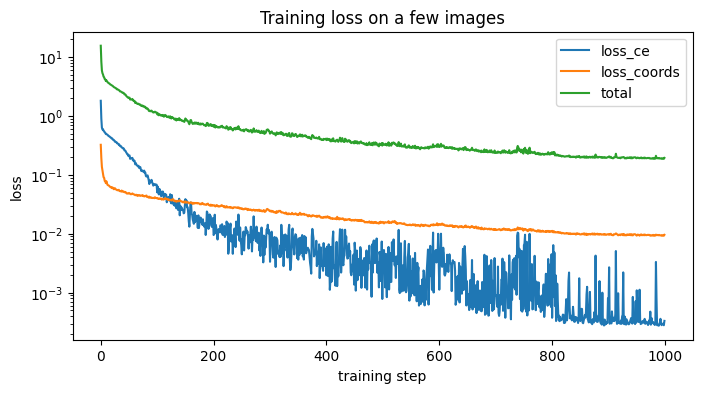

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4))
for key in history[0]:
    ax.plot([h[key] for h in history], label=key)
ax.set(xlabel="training step", ylabel="loss", yscale="log", title="Training loss on a few images")
ax.legend()
plt.show()

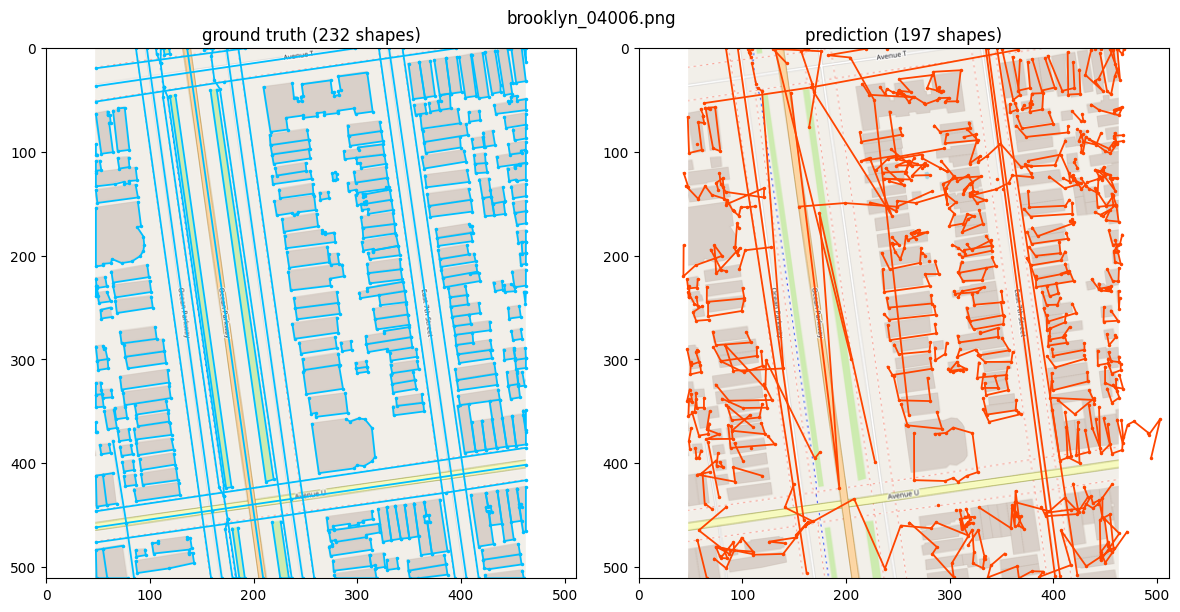

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import torch

idx = 0   # a training image; indices < N_IMAGES are the ones the model was trained on
record = dataset[idx]

# Generate a sequence for this image
model.eval()
with torch.no_grad():
    pred_tokens = model.forward_inference([record["image"].to(device)], use_cache=True)["gen_out"][0]

# Ground truth as the same kind of tokens: [x, y] for corners, 1 = separator, 2 = end
n = int(record["mask"].sum())
gt_tokens = [xy if t == 0 else t for xy, t in zip(record["target_seq"][:n].tolist(), record["token_labels"][:n].tolist())]

def to_shapes(tokens, size):
    """Split a token list into shapes (pixel coordinates) at separator / end tokens."""
    shapes, cur = [], []
    for tok in tokens:
        if isinstance(tok, (int, np.integer)):
            if cur:
                shapes.append(np.array(cur) * (size - 1))
            cur = []
        else:
            cur.append(tok)
    if cur:
        shapes.append(np.array(cur) * (size - 1))
    return shapes

size = record["image"].shape[-1]   # square after the loader's resize + pad
image = record["image"].permute(1, 2, 0).numpy()
name = dataset.coco.loadImgs(dataset.ids[idx])[0]["file_name"]

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, title, tokens, color in [(axes[0], "ground truth", gt_tokens, "deepskyblue"),
                                 (axes[1], "prediction", pred_tokens, "orangered")]:
    shapes = to_shapes(tokens, size)
    ax.imshow(image)
    for s in shapes:
        ax.plot(s[:, 0], s[:, 1], color=color, lw=1.3, marker=".", ms=3)
    ax.set(title=f"{title} ({len(shapes)} shapes)", xlim=(0, size - 1), ylim=(size - 1, 0))
fig.suptitle(name)
plt.tight_layout()
plt.show()

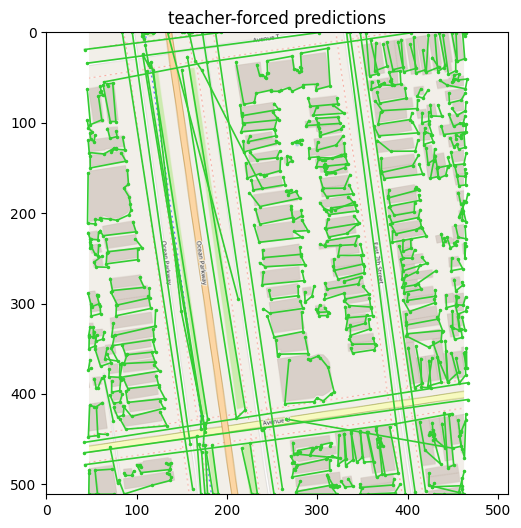

In [ ]:
rec = dataset[idx]
batch, extras = collate([rec])
model.eval()
with torch.no_grad():
    out = model([batch[0]["image"].to(device)], {k: v.to(device) for k, v in extras.items()})
n = int(extras["mask"][0].sum())
types = extras["token_labels"][0][:n].tolist()
tf_tokens = [xy if t == 0 else t for xy, t in zip(out["pred_coords"][0][:n].cpu().tolist(), types)]

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(batch[0]["image"].permute(1, 2, 0).numpy())
for s in to_shapes(tf_tokens, size):
    ax.plot(s[:, 0], s[:, 1], color="limegreen", lw=1.2, marker=".", ms=3)
ax.set(title="teacher-forced predictions", xlim=(0, size - 1), ylim=(size - 1, 0))
plt.show()

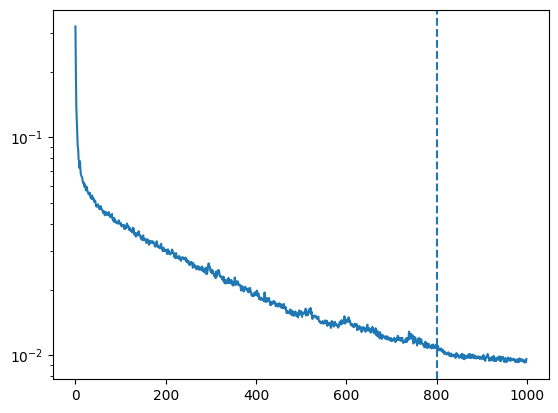

In [ ]:
import matplotlib.pyplot as plt
plt.semilogy([h["loss_coords"] for h in history]); plt.axvline(0.8 * STEPS, ls="--"); plt.show()

In [ ]:
batch, extras = next(iter(loader))
samples = [item["image"].to(device) for item in batch]
extras = {k: v.to(device) for k, v in extras.items()}

model.eval()
with torch.no_grad():
    out = model(samples, extras)               # teacher forced
mask = extras["token_labels"] == 0             # corner tokens
err = (out["pred_coords"][mask] - extras["target_seq"][mask]).abs() * IMAGE_SIZE
print(f"corner error in px: median {err.median():.1f}, mean {err.mean():.1f}, 90th pct {err.quantile(0.9):.1f}")
model.train()

corner error in px: median 1.8, mean 2.8, 90th pct 4.9


Raster2Seq(
  (transformer): DeformableTransformer(
    (encoder): DeformableTransformerEncoder(
      (layers): ModuleList(
        (0-5): 6 x DeformableTransformerEncoderLayer(
          (self_attn): MSDeformAttn(
            (sampling_offsets): Linear(in_features=256, out_features=256, bias=True)
            (attention_weights): Linear(in_features=256, out_features=128, bias=True)
            (value_proj): Linear(in_features=256, out_features=256, bias=True)
            (output_proj): Linear(in_features=256, out_features=256, bias=True)
          )
          (dropout1): Dropout(p=0.1, inplace=False)
          (norm1): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
          (linear1): Linear(in_features=256, out_features=1024, bias=True)
          (dropout2): Dropout(p=0.1, inplace=False)
          (linear2): Linear(in_features=1024, out_features=256, bias=True)
          (dropout3): Dropout(p=0.1, inplace=False)
          (norm2): LayerNorm((256,), eps=1e-05, elementwise_aff

In [ ]:
gt_tokens

[[0.16951867938041687, 0.0],
 [0.31134727597236633, 1.0],
 1,
 [0.19005562365055084, 0.0],
 [0.3131529986858368, 0.872300386428833],
 1,
 [0.20722946524620056, 0.0],
 [0.20868663489818573, 0.010311635211110115],
 [0.216036856174469, 0.02800174243748188],
 1,
 [0.216036856174469, 0.02800174243748188],
 [0.2219334840774536, 0.07365590333938599],
 1,
 [0.21647441387176514, 0.0],
 [0.216036856174469, 0.02800174243748188],
 1,
 [0.2219334840774536, 0.07365590333938599],
 [0.22928370535373688, 0.09134596586227417],
 [0.33523109555244446, 0.8236814141273499],
 [0.33523109555244446, 0.8443011045455933],
 1,
 [0.2219334840774536, 0.07365590333938599],
 [0.2204524725675583, 0.09134596586227417],
 [0.32639986276626587, 0.8280947804450989],
 [0.33523109555244446, 0.8443011045455933],
 1,
 [0.26615241169929504, 0.0],
 [0.4096303880214691, 1.0],
 1,
 [0.3153475224971771, 0.0],
 [0.31167200207710266, 0.014725119806826115],
 [0.3175686299800873, 0.06041548401117325],
 [0.3278534412384033, 0.0766223371

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
idx = 0
rec = dataset[idx]
batch, extras = collate([rec])          # the notebook's collate; uses a fresh copy of the record
model.eval()
with torch.no_grad():
    out = model([batch[0]["image"].to(device)], {k: v.to(device) for k, v in extras.items()})

n = int(extras["mask"][0].sum())
is_corner = extras["token_labels"][0][:n] == 0
err = (out["pred_coords"][0][:n].cpu() - extras["target_seq"][0][:n])[is_corner].abs()
size = batch[0]["image"].shape[-1]
print(f"teacher-forced corner error: {err.mean() * (size - 1):.1f} px (median {err.median() * (size - 1):.1f})")
print("last training losses:", history[-1])

teacher-forced corner error: 2.7 px (median 1.8)
last training losses: {'loss_ce': 0.0003331939224153757, 'loss_coords': 0.009595436044037342, 'total': 0.1935746818780899}


In [ ]:
tgt = extras["target_seq"][0][:n]
pred = out["pred_coords"][0][:n].cpu()
size = batch[0]["image"].shape[-1]

corner = extras["token_labels"][0][:n] == 0             # corner tokens
prev_is_corner = torch.roll(corner, 1, dims=0)
starts = corner & ~prev_is_corner                       # first corner of each shape
within = corner & prev_is_corner                        # corners that follow another corner

e = (pred - tgt).abs().mean(-1) * (size - 1)            # per-token error in pixels
print(f"shape starts: {e[starts].mean():.1f} px ({int(starts.sum())})   "
      f"within shapes: {e[within].mean():.1f} px ({int(within.sum())})")

# reference points: copy the previous corner / always guess the image centre
copy_err = (torch.roll(tgt, 1, dims=0) - tgt)[within].abs().mean() * (size - 1)
centre_err = (tgt[corner] - 0.5).abs().mean() * (size - 1)
print(f"copy-previous-corner: {copy_err:.1f} px | image-centre: {centre_err:.1f} px")

shape starts: 2.7 px (232)   within shapes: 2.7 px (822)
copy-previous-corner: 14.2 px | image-centre: 127.8 px


In [ ]:
types = extras["token_labels"][0][:n]
pred_types = out["pred_logits"][0][:n].argmax(-1).cpu()
for t, name in [(0, "corner"), (1, "separator"), (2, "end")]:
    m = types == t
    if m.any():
        print(f"{name:9s}: {(pred_types[m] == t).float().mean():.0%} predicted correctly ({int(m.sum())} tokens)")
print("predicted separators:", int((pred_types == 1).sum()), "| true separators:", int((types == 1).sum()))

corner   : 100% predicted correctly (1054 tokens)
separator: 100% predicted correctly (231 tokens)
end      : 100% predicted correctly (1 tokens)
predicted separators: 231 | true separators: 231


## Next steps

- If training runs and `loss_ce` falls, the pipeline works end to end. For `loss_coords` to fall clearly, use `PRETRAINED = True` and more `STEPS`. Real training uses `main_ddp.py` via `torchrun` on a GPU machine (see Raster2Seq's `tools/train_*.sh` and `tools/finetune_*.sh`).
- Stage 2 (labels): `--semantic_classes` = number of labels + 1, plus `--per_token_sem_loss --jointly_train`.

## Simple Test by Minsung Kim

In [ ]:
dataset = build_dataset(image_set=SPLIT, args=args)
_load_anns = dataset.coco.loadAnns
dataset.coco.loadAnns = lambda ids: copy.deepcopy(_load_anns(ids))   # see patches above
args.vocab_size = dataset.get_vocab_size()

# the sequence tensors to batch together (same as main_ddp.py's collator)
SEQ_KEYS = ["delta_x1", "delta_x2", "delta_y1", "delta_y2", "seq11", "seq21", "seq12", "seq22",
            "target_seq", "token_labels", "mask", "target_polygon_labels"]

def collate(batch):
    return batch, {k: torch.stack([item.pop(k) for item in batch]) for k in SEQ_KEYS}

loader = DataLoader(Subset(dataset, range(min(N_IMAGES, len(dataset)))),
                    batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate, num_workers=0)
print(len(loader.dataset), "images,", len(loader), "batches per pass")

Build waffle train dataset
loading annotations into memory...
Done (t=0.04s)
creating index...
index created!
2 images, 1 batches per pass


In [ ]:
Subset(dataset, 0)

Build waffle train dataset
loading annotations into memory...
Done (t=0.03s)
creating index...
index created!


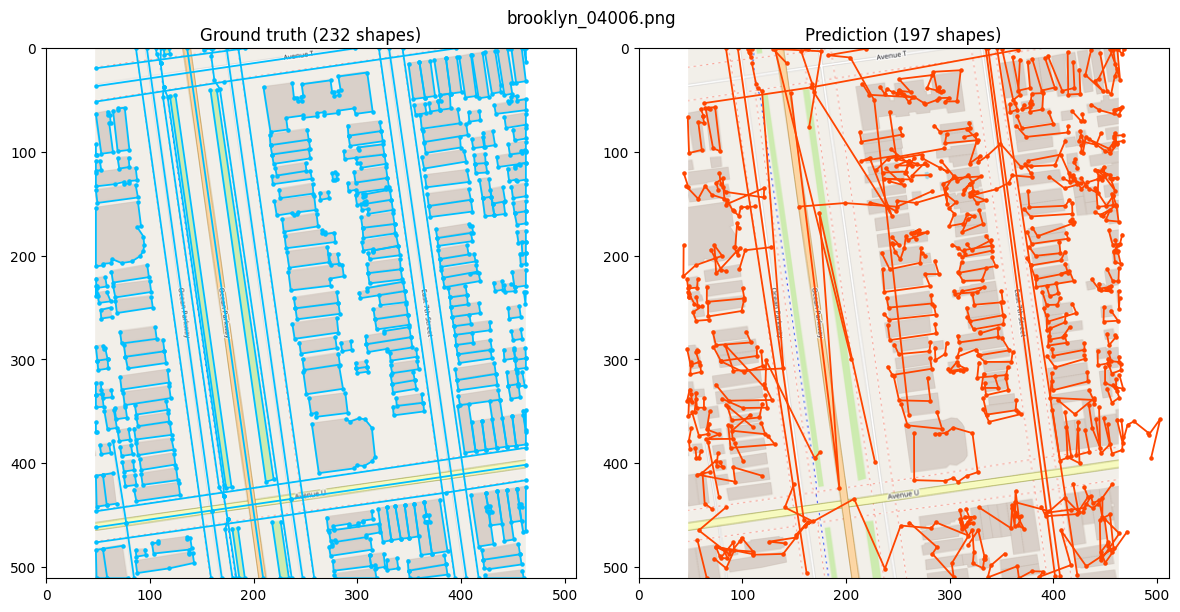

In [ ]:
import copy
import matplotlib.pyplot as plt
import numpy as np
import torch
from datasets import build_dataset

# Load the held-out test split.
test_dataset = build_dataset(image_set="train", args=args)

# Keep the original COCO annotations unchanged when the loader resizes them.
_load_test_anns = test_dataset.coco.loadAnns
test_dataset.coco.loadAnns = lambda ids: copy.deepcopy(_load_test_anns(ids))

# Select one test image. The mini test split contains 12 images (indices 0–11).
test_idx = 0
test_record = dataset[0]
test_image = test_record["image"].to(device)

# Generate a sequence from the image, using Raster2Seq's inference cache.
model.eval()
with torch.no_grad():
    result = model.forward_inference([test_image], use_cache=True)

# Split the ground-truth sequence at its shape-separator and end tokens.
n_gt = int(test_record["mask"].sum().item())
gt_xy = test_record["target_seq"][:n_gt].detach().cpu().numpy()
gt_types = test_record["token_labels"][:n_gt].detach().cpu().numpy()

def split_ground_truth(coords, token_types):
    shapes = []
    current = []

    for point, token_type in zip(coords, token_types):
        if int(token_type) == 0:  # Coordinate token
            current.append(point.tolist())
        elif int(token_type) in (1, 2):  # Shape separator or end token
            if current:
                shapes.append(current)
                current = []

    return shapes

def split_prediction(generated):
    shapes = []
    current = []

    for token in generated:
        if isinstance(token, (int, np.integer)):
            if int(token) in (1, 2):  # Shape separator or end token
                if current:
                    shapes.append(current)
                    current = []
        else:
            current.append([float(token[0]), float(token[1])])

    if current:
        shapes.append(current)

    return shapes

gt_shapes = split_ground_truth(gt_xy, gt_types)
pred_shapes = split_prediction(result["gen_out"][0])

# Convert normalized coordinates to pixels in the resized image.
height, width = test_record["image"].shape[-2:]

gt_shapes = [
    [[x * (width - 1), y * (height - 1)] for x, y in shape]
    for shape in gt_shapes
]
pred_shapes = [
    [[x * (width - 1), y * (height - 1)] for x, y in shape]
    for shape in pred_shapes
]

# Convert the input image tensor to a format Matplotlib can display.
image = test_record["image"].detach().cpu().permute(1, 2, 0).numpy()
image_name = test_dataset.coco.loadImgs(
    test_dataset.ids[test_idx]
)[0]["file_name"]

# Show the ground truth and prediction side by side.
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

for ax, title, shapes, color in [
    (axes[0], f"Ground truth ({len(gt_shapes)} shapes)", gt_shapes, "deepskyblue"),
    (axes[1], f"Prediction ({len(pred_shapes)} shapes)", pred_shapes, "orangered"),
]:
    ax.imshow(image)

    for shape in shapes:
        points = np.asarray(shape)
        if len(points) >= 2:
            ax.plot(points[:, 0], points[:, 1], color=color, linewidth=1.3)
            ax.scatter(points[:, 0], points[:, 1], color=color, s=5)

    ax.set_title(title)
    ax.set_xlim(0, width - 1)
    ax.set_ylim(height - 1, 0)
    ax.set_aspect("equal")

fig.suptitle(image_name)
plt.tight_layout()
plt.show()